# Práctica 1 – Parte 2: ataque adversario (FGSM) a MNIST

En esta parte entrenamos dos modelos sobre MNIST (una red neuronal convolucional y una SVM con núcleo gaussiano), programamos el ataque **FGSM** contra la red neuronal y comprobamos qué ocurre cuando clasificamos las imágenes adversarias con ambos modelos.

**Contenido del cuaderno**

0. Preparación de los datos (se cargan **una sola vez**).
1. Red neuronal (acierto ≥ 95 % y número de parámetros).
2. SVM con núcleo gaussiano.
3. Función FGSM.
4. Imágenes adversarias: predicción con la red y con la SVM, y visualización.

La numeración 1–4 coincide con los apartados del enunciado.

**Idea del ataque.** FGSM añade a cada imagen una perturbación $\eta=\epsilon\cdot\mathrm{signo}(\nabla_x L(x,w,y))$ que sube la pérdida lo máximo posible bajo la restricción $\|\eta\|_\infty\le\epsilon$. Cada píxel cambia como mucho $\epsilon$, así que a ojo la imagen casi no cambia, pero la red se equivoca.

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras import layers, models
from sklearn.svm import SVC

# fijamos la semilla de Python, NumPy y TensorFlow para que los resultados sean reproducibles
tf.keras.utils.set_random_seed(42)
# fuerza operaciones deterministas en TensorFlow (mismo resultado en cada ejecución)
tf.config.experimental.enable_op_determinism()

## 0. Preparación de los datos

Cargamos MNIST con `tensorflow.keras.datasets` (60.000 imágenes de entrenamiento y 10.000 de test, de 28×28 píxeles) y dividimos los píxeles entre 255 para pasar de $[0,255]$ a $[0,1]$.

Normalizar sirve para que todas las entradas tengan una escala parecida: así el descenso de gradiente con `learning_rate=0.1` es estable y el parámetro `gamma=0.01` de la SVM está bien calibrado (el núcleo gaussiano depende de la distancia entre imágenes, y esa distancia depende de la escala).

Cada modelo necesita la imagen en un formato distinto, así que **cargamos los datos una vez** y creamos dos "vistas" a partir de ellos:

| Variable | Forma | La usa |
|---|---|---|
| `x_train`, `x_test` | (N, 28, 28, 1) | red neuronal convolucional y FGSM |
| `x_train_svm`, `x_test_svm` | (N, 784) | SVM |

In [2]:
# cargamos MNIST (una sola vez para todo el cuaderno)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# normalizamos los píxeles de 0-255 a 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# vista para la SVM: cada imagen 28x28 se aplana en un vector de 784 números
x_train_svm = x_train.reshape(len(x_train), -1)
x_test_svm = x_test.reshape(len(x_test), -1)

# vista para la red convolucional: añadimos la dimensión del canal (28, 28) -> (28, 28, 1)
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Red neuronal:", x_train.shape, x_test.shape)
print("SVM:", x_train_svm.shape, x_test_svm.shape)

Red neuronal: (60000, 28, 28, 1) (10000, 28, 28, 1)
SVM: (60000, 784) (10000, 784)


## 1. Red neuronal

**Arquitectura** (distinta a la de clase, que usa BatchNormalization y Dropout y tiene más de 400.000 parámetros; aquí es una red mucho más pequeña):

`Conv 5×5 (8 filtros) → MaxPool 2×2 → Conv 3×3 (24 filtros) → MaxPool 2×2 → Flatten → Dense 64 → Dense 10 (softmax)`

**Entrenamiento:** descenso de gradiente estocástico (SGD) con $w \leftarrow w - \eta\,\nabla L$, $\eta=0.1$, función de pérdida entropía cruzada, 15 épocas, lotes de 64 y un 10 % del train reservado para validación.

In [ ]:
# definimos la arquitectura de la red
red_neuronas = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(8, (5, 5), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(24, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

# descenso de gradiente: w = w - eta * gradiente, con eta = learning_rate
red_neuronas.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# entrenamos reservando un 10% del train para validar
red_neuronas.fit(x_train, y_train, epochs=15, batch_size=64, validation_split=0.1)

# evaluamos en el conjunto de test
perdida, acierto = red_neuronas.evaluate(x_test, y_test)
print("Acierto en test:", acierto)

# guardamos el modelo por si queremos reutilizarlo sin volver a entrenar
red_neuronas.save("red_mnist.keras")

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9111 - loss: 0.2771 - val_accuracy: 0.9785 - val_loss: 0.0716
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9778 - loss: 0.0734 - val_accuracy: 0.9863 - val_loss: 0.0518
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9838 - loss: 0.0523 - val_accuracy: 0.9880 - val_loss: 0.0449
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9874 - loss: 0.0412 - val_accuracy: 0.9890 - val_loss: 0.0422
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9900 - loss: 0.0335 - val_accuracy: 0.9888 - val_loss: 0.0402
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9920 - loss: 0.0277 - val_accuracy: 0.9890 - val_loss: 0.0402
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9934 - loss: 0.0229 - val_accuracy: 0.9888 - val_loss: 0.0409
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9946 - loss: 0.0192 - val_accuracy

### 1.1 Número de parámetros

En una capa convolucional hay $(\text{alto}\cdot\text{ancho}\cdot\text{canales de entrada}+1)\cdot\text{filtros}$ parámetros (el $+1$ es el sesgo de cada filtro) y en una capa densa $(\text{entradas}+1)\cdot\text{neuronas}$. Las capas de pooling y Flatten no tienen parámetros.

| Capa | Salida | Cálculo | Parámetros |
|---|---|---|---|
| Conv 5×5, 8 filtros | 24×24×8 | $(5\cdot5\cdot1+1)\cdot8$ | 208 |
| MaxPool 2×2 | 12×12×8 | – | 0 |
| Conv 3×3, 24 filtros | 10×10×24 | $(3\cdot3\cdot8+1)\cdot24$ | 1.752 |
| MaxPool 2×2 | 5×5×24 | – | 0 |
| Flatten | 600 | – | 0 |
| Dense 64 | 64 | $(600+1)\cdot64$ | 38.464 |
| Dense 10 | 10 | $(64+1)\cdot10$ | 650 |
| **Total** | | | **41.074** |

Lo comprobamos con Keras.tras entrenar, `summary()` puede mostrar `Total params: 41.076`, porque suma 2 parámetros del optimizador SGD; los parámetros de la red son los 41.074 de `Trainable params` (y de `count_params()`).

In [4]:
# mostramos las capas y el número de parámetros
red_neuronas.summary()
print("Parámetros totales:", red_neuronas.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 8)      │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 24)     │         1,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 600)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        38,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,076 (160.46 KB)

 Trainable params: 41,074 (160.45 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

Parámetros totales: 41074


## 2. SVM con núcleo gaussiano

Usamos `SVC(kernel="rbf", C=10, gamma=0.01)`, los hiperparámetros de los apuntes (98,33 % de acierto en test). El núcleo gaussiano es $K(x,x')=\exp(-\gamma\|x-x'\|^2)$ y el entrenamiento resuelve el problema dual, donde solo los puntos con $\lambda_i>0$ (**vectores soporte**) intervienen en la predicción.

El entrenamiento tarda unos minutos porque usa las 60.000 imágenes.

In [5]:
# SVM con núcleo gaussiano (RBF) y los hiperparámetros de los apuntes
svm = SVC(kernel="rbf", C=10, gamma=0.01)

# entrenamos resolviendo el problema dual
svm.fit(x_train_svm, y_train)

# acierto en el conjunto de test
print("Acierto en test:", svm.score(x_test_svm, y_test))

# número de vectores soporte (puntos con lambda > 0)
print("Vectores soporte:", svm.support_vectors_.shape[0])

Acierto en test: 0.9833
Vectores soporte: 10867


## 3. Ataque FGSM

La función recibe el modelo, las imágenes `x`, sus etiquetas verdaderas `y` y el tamaño de la perturbación `epsilon`. Con `tf.GradientTape` calculamos el gradiente de la pérdida **respecto a la imagen** (no respecto a los pesos, que es lo que se hace al entrenar) y movemos cada píxel $\epsilon$ en la dirección de su signo. Por último recortamos a $[0,1]$ para que la imagen siga siendo válida.

Es un ataque de **caja blanca** contra la red: usa sus gradientes. Contra la SVM será un ataque *transferido*, porque las imágenes se generan con la red y no con la SVM.

In [6]:
def fgsm(modelo, x, y, epsilon):
    """Devuelve las imágenes x perturbadas con FGSM contra el modelo dado."""

    # pasamos las imágenes a tensor de TensorFlow
    x = tf.convert_to_tensor(x, dtype=tf.float32)

    # registramos las operaciones para poder derivar después
    with tf.GradientTape() as cinta:
        # le decimos a la cinta que derive respecto a la imagen
        cinta.watch(x)
        # predicción de la red (probabilidades de las 10 clases)
        prediccion = modelo(x, training=False)
        # pérdida con la etiqueta correcta, la misma que se usó al entrenar
        perdida = tf.keras.losses.sparse_categorical_crossentropy(y, prediccion)

    # gradiente de la pérdida respecto a la imagen
    gradiente = cinta.gradient(perdida, x)

    # FGSM: movemos cada píxel epsilon en la dirección del signo del gradiente
    x_adv = x + epsilon * tf.sign(gradiente)

    # recortamos a [0,1] para que siga siendo una imagen válida
    x_adv = tf.clip_by_value(x_adv, 0.0, 1.0)

    return x_adv.numpy()

## 4. Imágenes adversarias: predicción y visualización

Elegimos 6 imágenes del test al azar (con semilla fija), generamos sus versiones adversarias con la red y clasificamos las 12 imágenes (originales y adversarias) con **ambos modelos**.

`EPSILON` controla la intensidad del ataque: valores pequeños (0.05–0.1) apenas se notan a simple vista, valores mayores (0.2–0.3) se ven como ruido pero son mucho más eficaces. Puedes probar distintos valores.

In [7]:
# intensidad del ataque: cada píxel cambia como máximo EPSILON
EPSILON = 0.2

# elegimos 6 imágenes del test al azar, con semilla fija para que sea reproducible
rng = np.random.default_rng(42)
indices = rng.choice(len(x_test), size=6, replace=False)
x_orig = x_test[indices]
y_orig = y_test[indices]

# generamos las imágenes adversarias atacando la red neuronal
x_adv = fgsm(red_neuronas, x_orig, y_orig, EPSILON)

# comprobamos que ningún píxel ha cambiado más de EPSILON
print("Cambio máximo por píxel:", np.abs(x_adv - x_orig).max())

# predicciones de la red neuronal (clase con mayor probabilidad)
pred_rn_orig = np.argmax(red_neuronas.predict(x_orig, verbose=0), axis=1)
pred_rn_adv = np.argmax(red_neuronas.predict(x_adv, verbose=0), axis=1)

# predicciones de la SVM (necesita las imágenes aplanadas)
pred_svm_orig = svm.predict(x_orig.reshape(len(x_orig), -1))
pred_svm_adv = svm.predict(x_adv.reshape(len(x_adv), -1))

# tabla con las etiquetas reales y las predicciones de cada modelo
print("\nReal | RN orig | RN adv | SVM orig | SVM adv")
for i in range(len(indices)):
    print(f"{y_orig[i]:>4} | {pred_rn_orig[i]:>7} | {pred_rn_adv[i]:>6} | {pred_svm_orig[i]:>8} | {pred_svm_adv[i]:>7}")

Cambio máximo por píxel: 0.20000002

Real | RN orig | RN adv | SVM orig | SVM adv
   4 |       4 |      4 |        4 |       4
   9 |       9 |      8 |        9 |       8
   0 |       0 |      6 |        0 |       0
   8 |       8 |      8 |        8 |       8
   2 |       2 |      1 |        2 |       2
   2 |       2 |      3 |        2 |       2


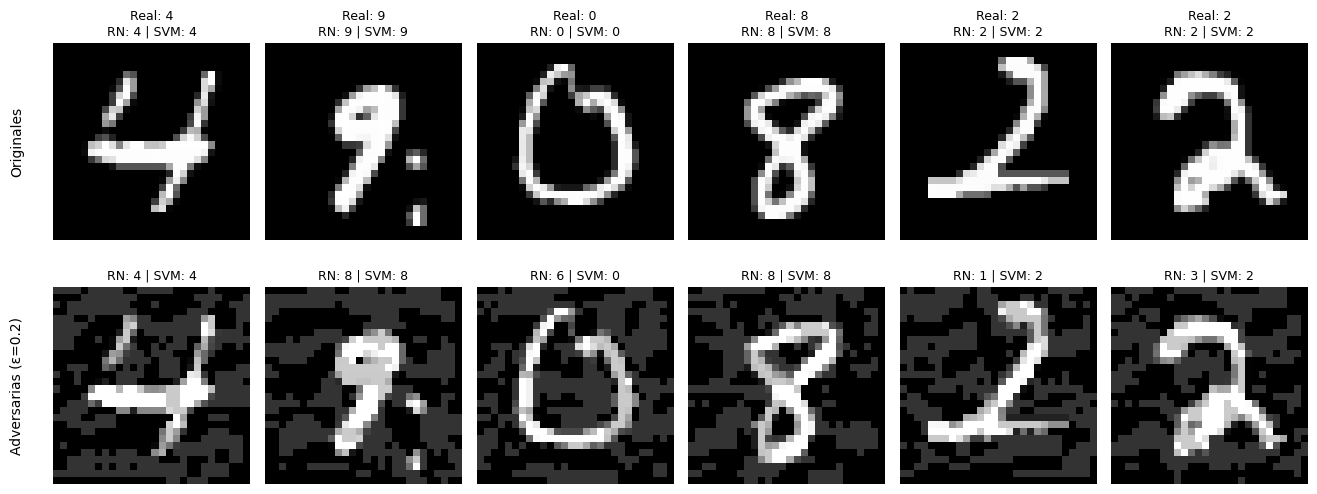

In [8]:
# dibujamos las originales (fila de arriba) y las adversarias (fila de abajo)
fig, ejes = plt.subplots(2, len(indices), figsize=(2.2 * len(indices), 5.4))

for i in range(len(indices)):
    # imagen original con las predicciones de ambos modelos
    ejes[0, i].imshow(x_orig[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ejes[0, i].set_title(f"Real: {y_orig[i]}\nRN: {pred_rn_orig[i]} | SVM: {pred_svm_orig[i]}", fontsize=9)
    ejes[0, i].axis("off")

    # imagen adversaria con las predicciones de ambos modelos
    ejes[1, i].imshow(x_adv[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ejes[1, i].set_title(f"RN: {pred_rn_adv[i]} | SVM: {pred_svm_adv[i]}", fontsize=9)
    ejes[1, i].axis("off")

ejes[0, 0].text(-0.15, 0.5, "Originales", transform=ejes[0, 0].transAxes, rotation=90, va="center", ha="right")
ejes[1, 0].text(-0.15, 0.5, f"Adversarias (ε={EPSILON})", transform=ejes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout()
plt.show()

### 4.1 Interpretación

- La red neuronal clasifica bien las originales, pero con la perturbación de FGSM suele equivocarse en casi todas las adversarias, porque la perturbación se ha calculado con **su propio gradiente**.
- La SVM gaussiana suele resistir mucho mejor: el ataque no está diseñado contra ella (es un ataque transferido), y su frontera de decisión es muy diferente a la de la red. En los apuntes se observa justo esto con todo el test: 1,1 % de acierto para la red frente a 93,2 % para la SVM gaussiana.
- Con 6 imágenes solo vemos ejemplos; para medir la eficacia del ataque de forma rigurosa hay que atacar el conjunto completo (punto 5, opcional).